# Loan Risk Profiling and Collection Management System

## Overview

### The problem

SACCOs (Savings and Credit Cooperative Organisations) lend their members' pooled savings to other
members, so every unpaid loan is a loss shared by all. Many SACCOs judge borrower risk informally
and keep loans in ledgers or spreadsheets, so a problem loan is noticed only after several missed
payments. Follow-up is unplanned: officers chase late payers in no fixed order, contacts go
unrecorded, and one borrower may get several calls a week while another gets none. Small arrears
that could have been recovered early grow into losses.

This notebook runs a Python system that helps a SACCO spot risky borrowers early and organise how
it collects overdue loans. The logic sits in the `src` package of classes; the notebook is the user
interface.

### Objectives and where each is met

| Objective | Section of this notebook |
|---|---|
| (a) Score each borrower's risk and probability of default (PD), the chance they stop paying | Risk model; Risk tiers; Portfolio profiling |
| (b) Group overdue loans into delinquency buckets by days past due (DPD) or months in arrears (MIA) | Delinquency buckets; Buckets by DPD and by MIA |
| (c) Apply collection rules before any reminder reaches a borrower | Daily collections run; Notification log |
| (d) Rank overdue loans for loan officers | Collections worklist |
| (e) Show analytics and 3 to 12 month loss projections on a dashboard | Debt projection; Dashboard |

### Reading and running it

- Run it from the top: restart the kernel, then run all cells.
- Real SACCO data is private, so the data is synthetic. `AS_OF`, set in the "Source data" section,
  is the business date everything is worked out for: 22 October 2026.
- The lists and the dashboard are interactive: use their filters, paging and export buttons.

## Notebook structure

The notebook runs in the same order as the system works: load the data, set the rules, score the
loans, then act on them and report. Each part below delivers one of the seven modules in the
proposal; the "Classes" column names the main classes in `src` that do the work.

| # | Section | What it does | Proposal module | Classes |
|---|---|---|---|---|
| 1 | Source data | Generates or loads the synthetic core-banking files and the reference data | (synthetic data, as proposed) | `SyntheticCoreBanking`, `CsvImport` |
| 2 | Customer List, Cases | Searchable lists of members and their loans | (the data behind every module) | `CustomerList`, `CaseList` |
| 3 | Contact, payment, promise-to-pay and treatment history | What happened on each loan so far | Notifications (past contacts) | `ContactHistory`, `PaymentHistory`, `PtpHistory`, `TreatmentHistory` |
| 4 | Collections policy | Buckets, risk tiers, profile rules, treatment matrix and contact limits, read from `configs/policy.json` and checked on loading | Delinquency buckets, Collection treatments | `Policy`, `BucketList`, `RiskTierList`, `ProfileRuleList`, `TreatmentList` |
| 5 | Risk model | Learns each loan's probability of default from repayment history, debt-to-income, savings habits and guarantor strength, and tests it on later months | Risk profiling | `FeatureBuilder`, `LogisticPdModel` |
| 6 | Portfolio profiling | Gives every open loan a DPD bucket, an MIA bucket, a risk tier and a profile | Risk profiling, Delinquency buckets | `Profiler` |
| 7 | Collections worklist | Ranks overdue loans by expected loss (PD times outstanding balance), filtered by bucket, risk tier and officer | Worklist | `Worklist` |
| 8 | Daily collections run | Chooses a treatment for each overdue loan, then checks payment status, pending promises and recent contacts before anyone is contacted | Collection treatments | `DunningEngine`, `ComplianceChecker` |
| 9 | Notification log | Records every message the run sent, queued, referred or held back, with filters | Notifications | `NotificationLog`, `NotificationList` |
| 10 | Debt projection | A roll-rate Markov chain that projects today's balance by bucket 3, 6 and 12 months ahead, with a back-test against real history | Debt projection | `RollRateModel` |
| 11 | Dashboard | Portfolio at risk, risk tiers, buckets by DPD and MIA, promise-to-pay results and the projection, with CSV and PDF export | Dashboard | `DashboardData`, `PortfolioDashboard` |

### How the build compares with the proposal

All seven proposed modules are built, and each is tested in `tests/`. The build goes further than
the proposal in three places: the compliance rules come from a policy file that is checked when
it loads, so the rules can change without changing code; the notification log also keeps the
messages that were held back and why; and the projection is back-tested against what really
happened. Two limits are worth knowing. The notification log covers the run in this notebook and
is not saved between sessions. The projection is close to what happened up to six months ahead
but pessimistic at twelve, as the back-test shows.

In [199]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [200]:
%pip install numpy
%pip install pandas
%pip install joblib
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrad

## Source data

The data files in `data/` stand in for the SACCO's core banking system. They are produced by
`SyntheticCoreBanking`, which simulates members saving and borrowing over two years. Every file
comes from the same simulated history, so balances, arrears, promises and collection activity
all agree with each other. Set `REGENERATE = True` to rebuild them; the fixed seed gives the
same files every time.

`AS_OF` is the business date the files describe. Every list and the risk model use it,
so the results don't change with the day the notebook is run.

In [201]:
from src.synthetic_core_banking import SyntheticCoreBanking, GeneratorSettings

AS_OF = GeneratorSettings().as_of      # the business date the data files describe
REGENERATE = False      # set to True to rebuild every file in data/ from the simulation

if REGENERATE:
    counts = SyntheticCoreBanking(GeneratorSettings(seed=2026)).write("data")
    print(counts)

### Data Load
***Load data from data files*** 


In [202]:
from src.csv_import import CsvImport

importer = CsvImport()

#Load KB and customer data
kb = importer.load_dir_data("kb")
cust_data = importer.load_dir_data("data")



## Customer List

***To do:Add descriptions of this section***

In [203]:
from src.display.customer_list import CustomerList

CustomerList(
    cust_data["customer"]["rows"], AS_OF, 25, 2,
    address_rows=cust_data["address"]["rows"],
    contact_rows=cust_data["contact"]["rows"],
    location_rows=kb["locations"]["rows"],
).show()

## Cases

Every loan case, most overdue first. Filter by account number, customer, loan type, status,
days past due (DPD) or outstanding balance.

In [204]:
from src.display.case_list import CaseList

CaseList(cust_data["case"]["rows"], cust_data["customer"]["rows"], kb["loan_types"]["rows"], list_page_size=25, filter_cols_per_row=2).show()

## Contact history

Every SMS, email and call made to customers, newest first, with the number or email used
and the outcome. Filter by account, customer, month, channel, outcome or words in the notes.

In [205]:
from src.display.contact_history import ContactHistory

ContactHistory(
    cust_data["contact_history"]["rows"],
    cust_data["case"]["rows"],
    cust_data["customer"]["rows"],
    contact_rows=cust_data["contact"]["rows"],
    list_page_size=25,
    filter_cols_per_row=3,
).show()

## Payment history

Every payment received, newest first. "Against PTP" shows whether the payment was made
against a promise to pay. Filter by account, customer, receipt reference, month, channel,
status or amount.

In [206]:
from src.display.payment_history import PaymentHistory

PaymentHistory(
    cust_data["payment_history"]["rows"],
    cust_data["case"]["rows"],
    cust_data["customer"]["rows"],
    list_page_size=25,
    filter_cols_per_row=3,
).show()

## Promise-to-pay history

Every promise to pay, latest promised date first. "Paid %" shows how much of each promise
was paid; over 100 means the customer paid more than promised. Filter by account, customer,
month promised, status, promised amount or paid %.

In [207]:
from src.display.ptp_history import PtpHistory

PtpHistory(
    cust_data["ptp"]["rows"],
    cust_data["case"]["rows"],
    cust_data["customer"]["rows"],
    list_page_size=25,
    filter_cols_per_row=3,
).show()

## Treatment history

Every collection treatment started on a case, newest first: what was done, who it was
assigned to, and how overdue the loan was when it started. "Days" is how long the treatment
ran, or has been running so far. Filter by account, customer, start month, treatment,
status, who it's assigned to, DPD or arrears at the start, or duration.

In [208]:
from src.display.treatment_history import TreatmentHistory

TreatmentHistory(
    cust_data["treatment_history"]["rows"],
    cust_data["case"]["rows"],
    cust_data["customer"]["rows"],
    list_page_size=25,
    filter_cols_per_row=3,
    treatment_type_rows=kb["treatment_type"]["rows"],
    as_of=AS_OF,
).show()

## Collections policy

The rules the system follows each day are kept in `configs/policy.json`, not in the code,
so they can change without changing any classes. The policy is checked when it loads,
so a mistake stops the notebook with a clear message instead of treating customers the wrong way.

In [209]:
from src.policy import Policy

policy = Policy.load("configs/policy.json", treatment_type_rows=kb["treatment_type"]["rows"])

### When the policy is wrong

Every check raises `PolicyError`, a subclass of the system's own `SaccoError`, with a message
that says what is wrong and where. The cell below loads copies of the policy with common mistakes
and shows how each is caught; the real policy above is unchanged.

In [ ]:
import copy
import json
from pathlib import Path

from src.exceptions import PolicyError, SaccoError

settings = json.loads(Path("configs/policy.json").read_text(encoding="utf-8"))
treatment_types = [row["type_id"] for row in kb["treatment_type"]["rows"]]

mistakes = {
    "a bucket without its upper limit": lambda p: p["buckets"]["edges"][1].pop("upper"),
    "buckets that overlap": lambda p: p["buckets"]["edges"][2].update(lower=25),
    "risk tiers out of order": lambda p: p["risk_tiers"][1].update(max_pd=0.005),
    "a treatment that doesn't exist": lambda p: p["treatment_matrix"]["low_risk"].update({"1-30": "PIGEON"}),
    "a channel without its weekly limit": lambda p: p["compliance"]["channels"]["SMS"].pop("max_per_week"),
}
for mistake, make in mistakes.items():
    broken = copy.deepcopy(settings)
    make(broken)
    try:
        Policy(broken, treatment_types)
        print(f"{mistake}: accepted (this should not happen)")
    except PolicyError as error:
        print(f"{mistake}: rejected. {error}")

# every error the system raises on purpose can also be caught as a SaccoError
try:
    Policy.load("configs/no_such_policy.json")
except SaccoError as error:
    print(f"{type(error).__name__}: {error}")

### Delinquency buckets

Loans are grouped by how many days they are overdue (DPD). Every loan falls in exactly one bucket.

In [210]:
from src.display.bucket_list import BucketList

BucketList(policy, list_page_size=25, filter_cols_per_row=3).show()

### Risk tiers

Each loan's probability of default (PD), from the risk model below, puts it in a tier from A
(lowest risk) to E (highest). The cut-offs are set in the policy, so they can change without
changing any code.

In [211]:
from src.display.risk_tier_list import RiskTierList

RiskTierList(policy, list_page_size=25, filter_cols_per_row=3).show()

### Profile rules

The rules are checked from the top. The first rule whose conditions all match decides the
customer's profile, and anyone no rule matches gets the default profile at the bottom.

In [212]:
from src.display.profile_rule_list import ProfileRuleList

ProfileRuleList(policy, list_page_size=25, filter_cols_per_row=3).show()

### Treatment matrix

The action taken for each profile and bucket. A combination that isn't listed gets no treatment.
"Fallback" is used when the main treatment can't be, for example an email when a customer
has no valid mobile number for an SMS.

In [213]:
from src.display.treatment_list import TreatmentList

TreatmentList(
    policy, list_page_size=25, filter_cols_per_row=3,
    treatment_type_rows=kb["treatment_type"]["rows"],
).show()

### Channel limits

How often each channel may be used to contact the same customer. These are the SACCO's own
policy settings, not legal limits.

In [214]:
from src.display.channel_limit_list import ChannelLimitList

ChannelLimitList(policy, list_page_size=25, filter_cols_per_row=3).show()

### General compliance rules

Rules that apply to every contact, whatever the channel: when customers may be contacted,
and which cases are never treated.

In [215]:
from src.display.general_rule_list import GeneralRuleList

GeneralRuleList(policy, list_page_size=25, filter_cols_per_row=3).show()

## Risk model

The model estimates each loan's probability of default (PD): the chance it reaches 90 days
past due within the next 6 months.

Each training row is one open loan at the end of one month, built only from what was known
that day:

- repayment history
- current DPD and MIA
- debt-to-income
- savings habits
- guarantor strength

The model learns from earlier months and is tested on later ones it never saw, the same way
it will be used: trained on the past, then used on today's loans.

In [216]:
import pandas as pd
from src.risk.feature_builder import FeatureBuilder

builder = FeatureBuilder(cust_data, kb, as_of=AS_OF, default_dpd=90, outcome_months=6)
rows = builder.training_set()

print(f"{len(rows):,} loan-months, {rows['defaulted'].sum():,} went on to default "
      f"({rows['defaulted'].mean():.1%})")
rows[FeatureBuilder.NUMERIC].describe().T[["mean", "min", "max"]].round(2)

8,906 loan-months, 713 went on to default (8.0%)


,mean,min,max
dpd,3.33,0.00,89.00
mia,0.15,0.00,12.00
outstanding_ratio,0.73,0.00,1.00
months_on_book,4.49,0.00,17.80
dti,0.36,0.06,1.48
monthly_income,966174.49,150000.00,4230000.00
savings_months_12,8.51,0.00,12.00
savings_to_income,1.64,0.00,3.63
guarantor_count,1.27,0.00,3.00
security_cover,1.22,0.00,3.00


In [217]:
from src.risk import LogisticPdModel

SPLIT_DATE = pd.Timestamp("2025-12-31")      # train on earlier months, test on later ones
train = rows[rows["observed_on"] < SPLIT_DATE]
test = rows[rows["observed_on"] >= SPLIT_DATE]
print(f"Training: {len(train):,} rows ({train['defaulted'].sum()} defaults), "
      f"months up to {train['observed_on'].max():%b %Y}")
print(f"Testing:  {len(test):,} rows ({test['defaulted'].sum()} defaults), "
      f"{test['observed_on'].min():%b %Y} to {test['observed_on'].max():%b %Y}")

model = LogisticPdModel(FeatureBuilder.NUMERIC, FeatureBuilder.CATEGORICAL).fit(train)
model.coefficients().head(12).round(3)

Training: 6,196 rows (539 defaults), months up to Nov 2025
Testing:  2,710 rows (174 defaults), Dec 2025 to Mar 2026


,feature,coefficient,effect
0,product_salary,-0.966,lowers risk
1,product_housing,-0.953,lowers risk
2,product_school_fees,0.947,raises risk
3,product_emergency,0.783,raises risk
4,repayment_frequency_weekly,-0.645,lowers risk
5,repayment_frequency_monthly,0.641,raises risk
6,employment_type_id_SALARIED,-0.553,lowers risk
7,dpd,0.479,raises risk
8,employment_type_id_CASUAL,0.462,raises risk
9,savings_months_12,-0.448,lowers risk


AUC on the test months: 0.909  (0.5 = guessing, 1.0 = perfect ranking)


band,loans,defaults,predicted PD %,actual default rate %
A,542,6,0.900000,1.100000
B,542,1,1.800000,0.200000
C,542,5,3.200000,0.900000
D,542,16,5.200000,3.000000
E,542,146,29.800000,26.900000


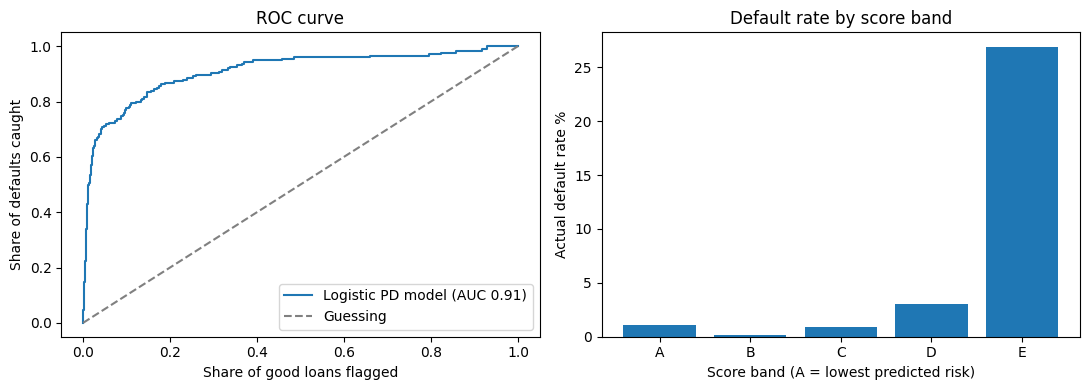

In [218]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

evaluation = model.evaluate(test, bands=5)
print(f"AUC on the test months: {evaluation.auc:.3f}  "
      f"(0.5 = guessing, 1.0 = perfect ranking)")

bands = evaluation.bands.assign(
    average_pd=lambda b: (100 * b["average_pd"]).round(1),
    default_rate=lambda b: (100 * b["default_rate"]).round(1),
)[["band", "loans", "defaults", "average_pd", "default_rate"]].rename(
    columns={"average_pd": "predicted PD %", "default_rate": "actual default rate %"})
display(bands.style.hide(axis="index"))

fpr, tpr, _ = roc_curve(test["defaulted"], model.predict_pd(test))
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
left.plot(fpr, tpr, label=f"Logistic PD model (AUC {evaluation.auc:.2f})")
left.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Guessing")
left.set(xlabel="Share of good loans flagged", ylabel="Share of defaults caught", title="ROC curve")
left.legend()
right.bar(bands["band"], bands["actual default rate %"])
right.set(xlabel="Score band (A = lowest predicted risk)", ylabel="Actual default rate %",
          title="Default rate by score band")
plt.tight_layout()
plt.show()

In [219]:
# the same model with no arrears information at all: today's DPD and MIA, the worst DPD so far,
# the share of months in arrears and broken promises
ARREARS = ["dpd", "mia", "worst_dpd_to_date", "arrears_share_to_date", "broken_ptps_to_date"]
without_arrears = [feature for feature in FeatureBuilder.NUMERIC if feature not in ARREARS]

no_arrears_model = LogisticPdModel(without_arrears, FeatureBuilder.CATEGORICAL).fit(train)
print(f"AUC without any arrears information: {no_arrears_model.evaluate(test).auc:.3f}")

AUC without any arrears information: 0.807


In [220]:
from pathlib import Path

MODEL_PATH = Path("models/pd_model.joblib")

final_model = LogisticPdModel(FeatureBuilder.NUMERIC, FeatureBuilder.CATEGORICAL).fit(rows)
final_model.save(MODEL_PATH)
print(f"Saved to {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1024:.0f} KB), trained on all {len(rows):,} rows")

Saved to models/pd_model.joblib (5 KB), trained on all 8,906 rows


### What the results show

The model ranks risk well on months it never saw (AUC about 0.91). Almost all defaults fall in
band E, where about 1 in 4 loans defaulted, against about 1 in 100 or fewer in bands A to C.

Arrears are strong signals, as expected. Without any arrears information (today's DPD and MIA,
the worst DPD so far, the share of months in arrears and broken promises), the model still reaches
an AUC of about 0.81 from the loan's terms, income, savings habits and guarantors, so those
features carry real information too.

The training months just before the split already see outcomes from the test months, so these
AUC figures are a little optimistic. The data is synthetic, so they show that the method works,
not how a real SACCO's loans would behave.

## Portfolio profiling

The profiler puts every open loan, at every month-end and on the business date, into a
delinquency bucket, a risk tier and a profile. The profile rules from the policy test facts
from three places: the loan itself (DPD, MIA, balances), the risk model (PD) and the contact
history (how often the customer answered in the last 90 days, and promises broken).

The model used here is `final_model`, trained on all the training rows above.

In [221]:
from src.profiling import Profiler

portfolio = Profiler(policy, final_model, builder, cust_data).portfolio()
today = portfolio[portfolio["business_date"] == pd.Timestamp(AS_OF)]

print(f"{len(today):,} open loans on {AS_OF:%d %B %Y}, {(today['dpd'] > 0).sum()} of them overdue")
pd.crosstab(today["profile"], today["tier"], margins=True, margins_name="total")

515 open loans on 22 October 2026, 97 of them overdue


tier,A,B,C,D,E,total
profile,,,,,,
broken_promises,0,0,1,0,0,1
current,122,185,99,12,0,418
high_risk,0,0,0,1,27,28
high_risk_unreachable,0,0,0,0,10,10
low_risk,11,10,16,10,1,48
medium_risk,0,0,0,2,2,4
medium_risk_large_balance,0,0,0,4,2,6
total,133,195,116,29,42,515


### Buckets by DPD and by MIA

DPD counts the days since the oldest unpaid instalment fell due. MIA divides the arrears by the
loan's monthly instalment, so it measures how much is owed rather than how long. The two mostly
agree. They differ for lump-sum loans: the whole balance falls due at once, so a few days late
can already mean several months of repayments in arrears.

In [222]:
pd.crosstab(today["bucket"], today["mia_bucket"]).rename_axis(index="by DPD", columns="by MIA")

by MIA,1-30,31-60,61-90,90+,current
by DPD,,,,,
1-30,47,0,1,1,0
31-60,3,6,0,1,0
61-90,0,0,3,0,0
90+,3,1,6,25,0
current,0,0,0,0,418


## Collections worklist

The overdue loans in the order officers should work them: highest expected loss first, where
expected loss is PD times the outstanding balance. It assumes nothing is recovered once a loan
defaults, so it ranks loans rather than estimating a provision. Filter by officer, bucket, risk
tier or profile; the rank stays each loan's place in the whole list.

In [223]:
from src.display.worklist import Worklist

Worklist(portfolio, AS_OF, list_page_size=25, filter_cols_per_row=3).show()

## Daily collections run

Each morning the system decides what to do about every overdue loan, in three steps:

1. **Dunning:** the treatment matrix gives each overdue loan a treatment for its profile and
   bucket. If the customer can't be reached on that channel (no valid mobile for an SMS or call,
   no email for an email), the policy's fallback treatment is used instead.
2. **Compliance:** every proposed action goes through the contact rules: case status, a pending
   promise to pay, contact hours, channel limits, the minimum gap between contacts and the daily
   cap. The first rule that fails blocks the action and records why.
3. **Notifications:** each decision is written to the notification log: messages sent, calls
   queued for an officer, referrals to the agency or legal department, and actions held back.

The run below is the start-of-day run on the morning after the business date.

In [224]:
from datetime import datetime, time, timedelta

from src.compliance import ComplianceChecker
from src.dunning import DunningEngine
from src.notifications import NotificationLog

RUN_AT = datetime.combine(AS_OF + timedelta(days=1), time(9, 0))

actions = DunningEngine(policy, cust_data["contact"]["rows"]).propose(today, RUN_AT)
checker = ComplianceChecker(policy, cust_data["contact_history"]["rows"], cust_data["case"]["rows"],
                            cust_data["ptp"]["rows"])
decisions = checker.check_all(actions)

notifications = NotificationLog(today, cust_data["customer"]["rows"], cust_data["contact"]["rows"])
notifications.record_all(checker.decisions)

print(f"Run at {RUN_AT:%A %d %B %Y %H:%M}: {len(actions)} actions proposed, "
      f"{decisions['allowed'].sum()} allowed, {(~decisions['allowed']).sum()} blocked")
pd.crosstab(decisions["treatment"], decisions["blocked_by"].replace("", "allowed"), margins=True,
            margins_name="total")

Run at Friday 23 October 2026 09:00: 68 actions proposed, 57 allowed, 11 blocked


blocked_by,Minimum gap,allowed,total
treatment,,,
CALL,0,10,10
DCA,0,8,8
EMAIL,0,1,1
LEGAL,0,1,1
SMS,11,37,48
total,11,57,68


### Notification log

Every message from the run, newest first. "Status" is SENT for an SMS or email, QUEUED for a call
an officer has to make, REFERRED for a case handed to the agency or legal department, and BLOCKED
when a compliance rule held it back, with the rule and the reason.

In [225]:
from src.display.notification_list import NotificationList

NotificationList(notifications, list_page_size=25, filter_cols_per_row=3).show()

## Debt projection

A roll-rate model projects where today's balance will be in the coming months. Every month-end
snapshot puts a loan in a state: one of the buckets while it is open, or SETTLED or WRITTEN_OFF
once it closes. The roll rates are the share of each bucket's balance found in each state a month
later. Together they form the transition matrix of a Markov chain [1], [2]: multiplying today's
balances by it once gives next month, twice gives the month after, and so on.

Each row below adds up to 100%: of the balance in that bucket, how much was in each state a month
later. SETTLED and WRITTEN_OFF are final: a closed loan stays closed.

In [226]:
from src.risk import RollRateModel

roll_rates = RollRateModel(policy).fit(cust_data["case_snapshot"]["rows"])
print(f"Learnt from {roll_rates.transitions:,} month-to-month moves")
(100 * roll_rates.matrix).round(1)

Learnt from 12,328 month-to-month moves


next_state,current,1-30,31-60,61-90,90+,SETTLED,WRITTEN_OFF
state,,,,,,,
current,89.7,9.3,0.1,0.0,0.0,0.9,0.0
1-30,75.4,8.7,14.5,0.1,0.0,1.2,0.0
31-60,16.9,6.9,7.1,67.3,0.1,1.7,0.0
61-90,2.1,5.4,0.1,7.7,82.8,1.9,0.0
90+,0.7,0.6,0.0,0.0,95.1,2.2,1.5
SETTLED,0.0,0.0,0.0,0.0,0.0,100.0,0.0
WRITTEN_OFF,0.0,0.0,0.0,0.0,0.0,0.0,100.0


### Projection of today's loans

The projection follows the loans open today. New lending isn't included, and repayments that
don't close a loan aren't modelled, so it shows where today's balance ends up rather than how
big the book will be.

In [227]:
start = roll_rates.balances(today)
projection = roll_rates.project(start, months=12)

display((projection.loc[[0, 3, 6, 12]] / 1e6).round(1).rename_axis("months ahead")
        .style.set_caption("Balance in each state, UGX million"))
roll_rates.expected_write_offs(start)

,current,1-30,31-60,61-90,90+,SETTLED,WRITTEN_OFF
months ahead,,,,,,,
0,1935.000000,160.300000,20.200000,11.900000,227.200000,0.000000,0.000000
3,1793.700000,192.400000,32.000000,23.300000,231.400000,71.800000,10.000000
6,1701.000000,182.900000,30.500000,22.900000,254.100000,142.300000,20.600000
12,1533.600000,165.200000,27.600000,20.700000,284.000000,279.100000,44.400000


,months ahead,written off (UGX),share of open balance %
0,3,10030690,0.4
1,6,20619597,0.9
2,12,44366029,1.9


### Back-test

To check the method, the model is fitted only on the month-ends up to 30 September 2025 and
projected from there. The loans open on that date are then followed through the next 12 months
of real snapshots, each keeping its starting balance, and the two are compared as shares of the
starting balance.

In [228]:
BACKTEST_FROM = pd.Timestamp("2025-09-30")

past = RollRateModel(policy).fit(cust_data["case_snapshot"]["rows"], until=BACKTEST_FROM)
snapshots = past.states_of(cust_data["case_snapshot"]["rows"])
open_then = snapshots[(snapshots["snapshot_date"] == BACKTEST_FROM) & ~snapshots["state"].isin(past.CLOSED_STATES)]
start_then = past.balances(open_then, state_column="state")

projected = past.project(start_then, months=12)
actual = past.actual_path(cust_data["case_snapshot"]["rows"], BACKTEST_FROM, months=12)
pd.DataFrame({
    (state, kind): (100 * frame.loc[[3, 6, 12], state] / start_then.sum()).round(1)
    for state in ["90+", "SETTLED", "WRITTEN_OFF"]
    for kind, frame in (("projected %", projected), ("actual %", actual))
}).rename_axis("months ahead")

90+              SETTLED          WRITTEN_OFF         
             projected % actual % projected % actual % projected % actual %
months ahead                                                               
3                    6.0      7.4         2.7      3.8         0.3      0.2
6                    8.8      8.0         5.4      9.4         0.9      0.6
12                  12.8      7.3        10.9     27.3         2.8      1.2

Up to six months the projection is close to what happened: 0.9% of the balance projected
to be written off against 0.6% actual, and 8.8% in 90+ against 8.0%. At twelve months it is
pessimistic (2.8% written off against 1.2%) and expects far too little to be paid off (10.9%
against 27.3%). The roll rates weight each move by the loan's balance when it moves, and a loan
about to be paid off has little left, so the chain moves little balance into SETTLED. The 3 and 6
month figures are the ones to plan with; the 12-month figure is an upper estimate.

## Dashboard

The portfolio at a glance for any business date, filtered by officer, profile, bucket or risk
tier: headline figures, portfolio at risk over time, buckets by DPD and MIA, risk tiers, the
collections activity in the period, the compliance results of the latest run and, for the
latest business date, the roll-rate projection. Export saves the current view as CSV files or a
PDF report in `export/`.

In [229]:
from src.dashboard import DashboardData, PortfolioDashboard

PortfolioDashboard(DashboardData(portfolio, cust_data, decisions, roll_rates)).show()

## References

District data: Uganda administrative boundaries, Humanitarian Data Exchange, https://data.humdata.org/dataset/cod-ab-uga

[1] L. C. Thomas, A. Matuszyk, M. C. So, C. Mues, and A. Moore, "Modelling repayment patterns in the collections process for unsecured consumer debt: A case study," *Eur. J. Oper. Res.*, vol. 249, no. 2, pp. 476–486, Mar. 2016, doi: 10.1016/j.ejor.2015.09.013.

[2] R. M. Cyert, H. J. Davidson, and G. L. Thompson, "Estimation of the Allowance for Doubtful Accounts by Markov Chains," *Manage. Sci.*, vol. 8, no. 3, pp. 287–303, Apr. 1962, doi: 10.1287/mnsc.8.3.287.